In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler


In [ ]:
df = pd.read_csv('dataset/Adult Census Income.csv')

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.shape

(32561, 15)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [6]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [7]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

In [8]:
df.duplicated().sum()

np.int64(24)

In [9]:
df.drop_duplicates(inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [10]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [11]:
col ='workclass'
print(df[col].unique())

<ArrowStringArray>
[               '?',          'Private',        'State-gov',
      'Federal-gov', 'Self-emp-not-inc',     'Self-emp-inc',
        'Local-gov',      'Without-pay',     'Never-worked']
Length: 9, dtype: str


In [12]:
df['workclass'].fillna('most_frequent_value', inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\4056585910.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['workclass'].fillna('most_frequent_value', inplace=True)


0              ?
1        Private
2              ?
3        Private
4        Private
          ...   
32556    Private
32557    Private
32558    Private
32559    Private
32560    Private
Name: workclass, Length: 32537, dtype: str

In [13]:
col ='occupation'
print(df[col].unique())


<ArrowStringArray>
[                '?',   'Exec-managerial', 'Machine-op-inspct',
    'Prof-specialty',     'Other-service',      'Adm-clerical',
      'Craft-repair',  'Transport-moving', 'Handlers-cleaners',
             'Sales',   'Farming-fishing',      'Tech-support',
   'Protective-serv',      'Armed-Forces',   'Priv-house-serv']
Length: 15, dtype: str


In [14]:
df['occupation'].fillna('most_frequent_value', inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\1334316450.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['occupation'].fillna('most_frequent_value', inplace=True)


0                        ?
1          Exec-managerial
2                        ?
3        Machine-op-inspct
4           Prof-specialty
               ...        
32556      Protective-serv
32557         Tech-support
32558    Machine-op-inspct
32559         Adm-clerical
32560         Adm-clerical
Name: occupation, Length: 32537, dtype: str

In [15]:
col ='native.country'
print(df[col].unique())


<ArrowStringArray>
[             'United-States',                          '?',
                     'Mexico',                     'Greece',
                    'Vietnam',                      'China',
                     'Taiwan',                      'India',
                'Philippines',            'Trinadad&Tobago',
                     'Canada',                      'South',
         'Holand-Netherlands',                'Puerto-Rico',
                     'Poland',                       'Iran',
                    'England',                    'Germany',
                      'Italy',                      'Japan',
                       'Hong',                   'Honduras',
                       'Cuba',                    'Ireland',
                   'Cambodia',                       'Peru',
                  'Nicaragua',         'Dominican-Republic',
                      'Haiti',                'El-Salvador',
                    'Hungary',                   'Columbia',
     

In [16]:
df['native.country'].fillna('Unknown', inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\588202822.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['native.country'].fillna('Unknown', inplace=True)


0        United-States
1        United-States
2        United-States
3        United-States
4        United-States
             ...      
32556    United-States
32557    United-States
32558    United-States
32559    United-States
32560    United-States
Name: native.country, Length: 32537, dtype: str

In [17]:
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\4185899704.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [18]:
df.drop(columns=['fnlwgt'], inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23720\2849616134.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['fnlwgt'], inplace=True)


In [19]:
df.isnull().sum()



age               0
workclass         0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [20]:
df['income'].unique()

<ArrowStringArray>
['<=50K', '>50K']
Length: 2, dtype: str

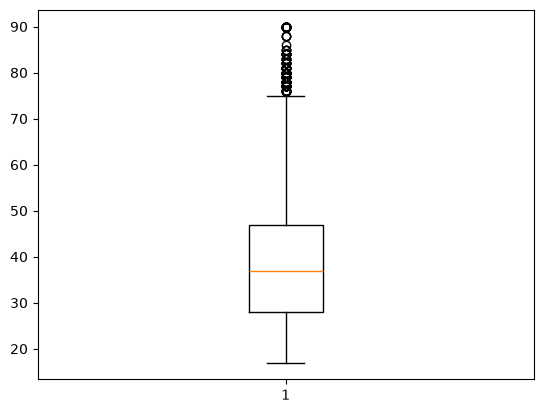

In [21]:
plt.boxplot(df['age'])
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))


sns.boxplot(data=df, x='income', y='hours.per.week')
plt.title('hours.per.week vs income')
plt.tight_layout()
plt.show()



In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='income', y='age')
plt.title('age vs income')
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='education', hue='income', order=df['education'].value_counts().index)
plt.xticks(rotation=45)
plt.title('Education vs Income')
plt.tight_layout()
plt.show()

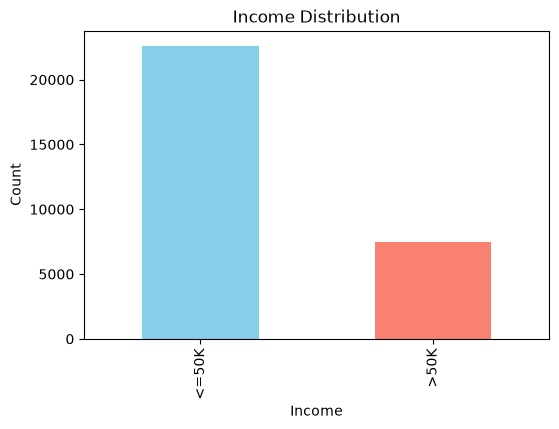

In [26]:
plt.figure(figsize=(6, 4))
df['income'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.show()

In [27]:
from sklearn.preprocessing import LabelEncoder

le_target = LabelEncoder()
y = le_target.fit_transform(df['income'])

In [28]:
X = df.drop(columns=['income'])
y = df['income']

In [29]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [30]:
le_target = LabelEncoder()
y = le_target.fit_transform(y)

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [32]:
model = LogisticRegression(max_iter=1000,
                           C=1.0,
                           penalty="l2",

                           )

In [33]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)



In [34]:
from imblearn.under_sampling import RandomUnderSampler

# بعد تقسيم البيانات لـ Train و Test
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

print("X_train_rus = ", X_train_rus.shape, " y_train_rus = ", y_train_rus.shape)

X_train_rus =  (12116, 95)  y_train_rus =  (12116,)


In [35]:
scaler = StandardScaler()

In [36]:
X_train_scaled = scaler.fit_transform(X_train_resampled)

In [37]:

X_train_scaled = scaler.fit_transform(X_train_rus)


X_test_scaled = scaler.transform(X_test)

In [38]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [39]:
model1 = LogisticRegression(class_weight='balanced', max_iter=1000)
model1.fit(X_train, y_train)
y_pred1 = model1.predict(X_test)







In [40]:

print('Accuracy:', accuracy_score(y_test, y_pred1))
print('\nClassification Report:\n', classification_report(y_test, y_pred1))

Accuracy: 0.8078964830789648

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.80      0.86      4580
           1       0.57      0.84      0.68      1448

    accuracy                           0.81      6028
   macro avg       0.75      0.82      0.77      6028
weighted avg       0.85      0.81      0.82      6028



In [41]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(X_train, y_train)
y_pred_knn = model_knn.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_knn))
print('\nClassification Report:\n', classification_report(y_test, y_pred_knn))





Accuracy: 0.8200066357000664

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.90      0.88      4580
           1       0.64      0.58      0.61      1448

    accuracy                           0.82      6028
   macro avg       0.75      0.74      0.74      6028
weighted avg       0.81      0.82      0.82      6028



In [42]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.naive_bayes import GaussianNB


model_nb = GaussianNB()
model_nb.fit(X_train, y_train)
y_pred_nb = model_nb.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_nb))
print('\nClassification Report:\n', classification_report(y_test, y_pred_nb))

Accuracy: 0.41721964167219644

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.24      0.39      4580
           1       0.29      0.97      0.44      1448

    accuracy                           0.42      6028
   macro avg       0.62      0.60      0.42      6028
weighted avg       0.80      0.42      0.40      6028



In [ ]:
# X_train / X_test are already scaled in the previous cells
X_train_scaled = X_train
X_test_scaled = X_test

In [8]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Lasso": LogisticRegression(penalty='l1', solver='liblinear'),
    "Ridge": RidgeClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVC(kernel='rbf', C=1),
    "Decision Tree": DecisionTreeClassifier(criterion='gini', max_depth=10),
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [ ]:
clf_results = []
clf_preds = {}

for name, model in clf_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    clf_preds[name] = y_pred

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

clf_results_df = pd.DataFrame(clf_results).sort_values(by='F1 Score', ascending=False)
clf_results_df.reset_index(drop=True, inplace=True)
clf_results_df

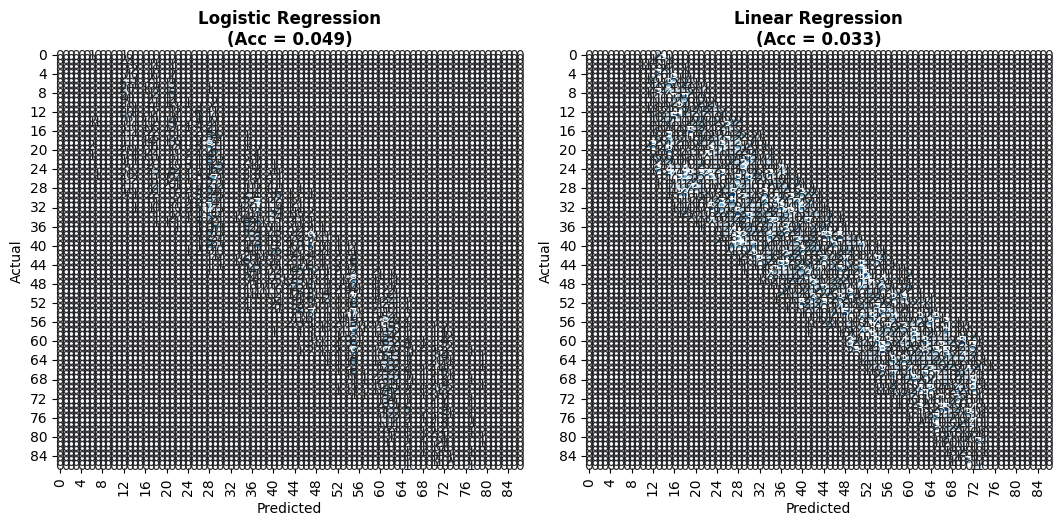

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix

fig, axes = plt.subplots(5, 3, figsize=(16, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(clf_preds.items()):
  # تحويل القيم لأعداد صحيحة لتفادي أي تعارض في الأنواع
  y_test_int = np.array(y_test).astype(int)
  y_pred_int = np.array(y_pred).astype(int)

  cm = confusion_matrix(y_test_int, y_pred_int)

  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i])

  acc = accuracy_score(y_test_int, y_pred_int)
  axes[i].set_title(f'{name}\n(Acc = {acc:.3f})', fontweight='bold')
  axes[i].set_xlabel('Predicted')
  axes[i].set_ylabel('Actual')

for j in range(len(clf_preds), len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Model comparison (F1)

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=clf_results_df, x='F1 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('F1 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in clf_models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='f1', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV F1': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV F1', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Lasso": {"C": [0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [0.1, 1, 10]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(clf_models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

base_model = clone(clf_models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p, zero_division=0),
                 'Recall': recall_score(y_test, p, zero_division=0),
                 'F1': f1_score(y_test, p, zero_division=0)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

y_pred = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
from sklearn.metrics import confusion_matrix

if hasattr(best_model, 'predict_proba'):
    scores = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    scores = best_model.decision_function(X_test_scaled)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- Accuracy = {acc:.3f}: {acc*100:.1f}% of all predictions are correct.")
print(f"- Precision = {prec:.3f}: when the model predicts the positive class, it is right {prec*100:.1f}% of the time ({fp} false alarms).")
print(f"- Recall = {rec:.3f}: the model finds {rec*100:.1f}% of the real positive cases and misses {fn}.")
print(f"- F1 = {f1:.3f}: the balance between precision and recall.")
print(f"- ROC-AUC = {roc_auc_score(y_test, scores):.3f}: the chance that a random positive case is ranked above a random negative one.")
print(f"- Average Precision (PR curve) = {average_precision_score(y_test, scores):.3f}: more reliable than accuracy when the classes are imbalanced.")
if rec < prec:
    print("- Recall is lower than precision: the model is careful but misses some positive cases.")
else:
    print("- Precision is lower than recall: the model catches most positive cases but raises some false alarms.")